<a href="https://colab.research.google.com/github/dimassatrio1209-cmd/fsd-tugaskelompoklineardanlogisticregression/blob/main/FSD_TugasKelompok_B_LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok: Logistic Regression
**Anggota Kelompok:**
1. Muhammad Dimas Satrio Domargo (25523262)
2. Abi Manyu Maheswara Ghoevara (25523084)
3. Pradhipta Widya Satria(23523129)

## B1. Deskripsi Dataset
* **Asal Dataset:** Dataset bawaan dari library `seaborn` bernama `titanic`.
* **Jumlah Baris dan Kolom:** 891 baris dan 15 kolom.
* **Arti Fitur Utama:** `pclass` (kelas tiket), `sex` (jenis kelamin), `age` (umur), `fare` (harga tiket).
* **Variabel Target:** `survived` (0 = Tidak selamat, 1 = Selamat). Ini adalah target kategorikal biner.

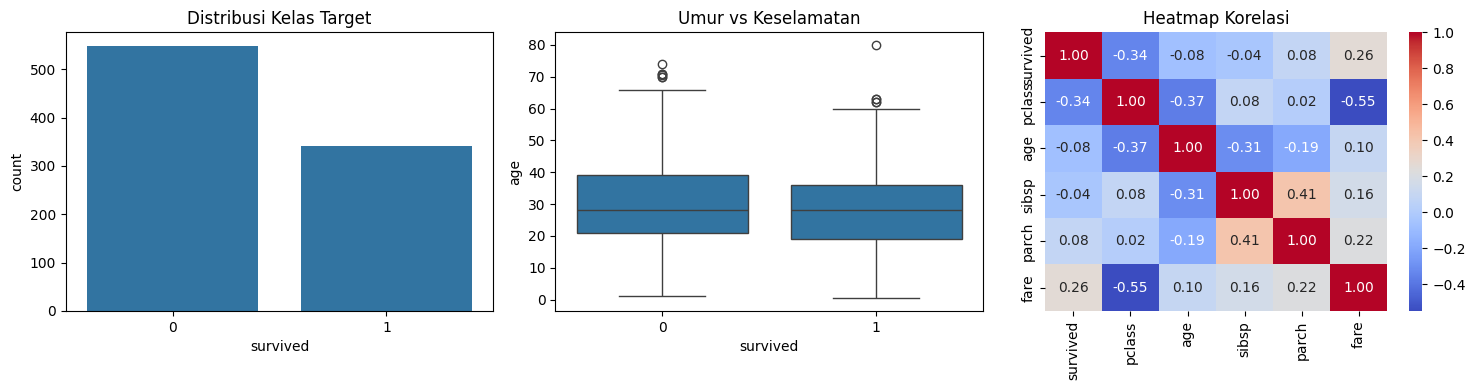


--- Model Logistic Regression ---
      Fitur  Koefisien
0    pclass  -0.996456
1       age  -0.502452
2      fare   0.189417
3     sibsp  -0.265403
4     parch  -0.107772
5  sex_male  -2.550358

Interpretasi: Koefisien negatif (misal sex_male) mengurangi peluang selamat (kelas 1). Koefisien pclass yang membesar (kelas lebih rendah) juga menekan peluang selamat.

--- Evaluasi Klasifikasi ---
Accuracy : 0.80
Precision: 0.73
Recall   : 0.78
F1-Score : 0.76
ROC-AUC  : 0.85


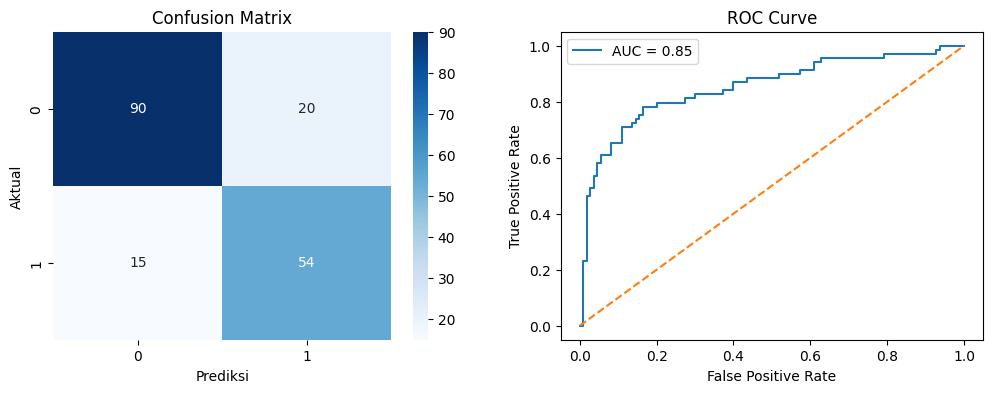

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

# B2. Eksplorasi dan Visualisasi Data
df_titanic = sns.load_dataset('titanic')

plt.figure(figsize=(15, 4))
# 1. Bar chart distribusi kelas
plt.subplot(1, 3, 1)
sns.countplot(x='survived', data=df_titanic)
plt.title('Distribusi Kelas Target')

# 2. Box plot fitur numerik per kelas
plt.subplot(1, 3, 2)
sns.boxplot(x='survived', y='age', data=df_titanic)
plt.title('Umur vs Keselamatan')

# 3. Heatmap
plt.subplot(1, 3, 3)
sns.heatmap(df_titanic.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi')
plt.tight_layout()
plt.show()

# B3 & B4. Preprocessing & Pemilihan Fitur
# Memilih fitur yang relevan secara logika dan korelasi
features = ['pclass', 'sex', 'age', 'fare', 'sibsp', 'parch', 'survived']
df_t = df_titanic[features].copy()

# Mengisi missing values (Umur diisi dengan median)
df_t['age'] = df_t['age'].fillna(df_t['age'].median())

# Encoding categorical (sex)
df_t = pd.get_dummies(df_t, drop_first=True)

X_log = df_t.drop('survived', axis=1)
y_log = df_t['survived']

# Scaling fitur numerik (wajib untuk logreg agar konvergen)
scaler_log = StandardScaler()
X_log[['age', 'fare']] = scaler_log.fit_transform(X_log[['age', 'fare']])

# B5. Pembagian Data (Stratify sangat penting untuk klasifikasi)
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)

# B6. Pemodelan (Class weight balanced jika kelas agak timpang)
model_log = LogisticRegression(class_weight='balanced')
model_log.fit(X_train_l, y_train_l)

print("\n--- Model Logistic Regression ---")
coef_log = pd.DataFrame({'Fitur': X_log.columns, 'Koefisien': model_log.coef_[0]})
print(coef_log)
print("\nInterpretasi: Koefisien negatif (misal sex_male) mengurangi peluang selamat (kelas 1). Koefisien pclass yang membesar (kelas lebih rendah) juga menekan peluang selamat.")

# B7. Evaluasi
y_pred_l = model_log.predict(X_test_l)
y_proba_l = model_log.predict_proba(X_test_l)[:, 1]

print("\n--- Evaluasi Klasifikasi ---")
print(f"Accuracy : {accuracy_score(y_test_l, y_pred_l):.2f}")
print(f"Precision: {precision_score(y_test_l, y_pred_l):.2f}")
print(f"Recall   : {recall_score(y_test_l, y_pred_l):.2f}")
print(f"F1-Score : {f1_score(y_test_l, y_pred_l):.2f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_l, y_proba_l):.2f}")

# Visualisasi Confusion Matrix & ROC
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix(y_test_l, y_pred_l), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix'); plt.xlabel('Prediksi'); plt.ylabel('Aktual')

plt.subplot(1, 2, 2)
fpr, tpr, _ = roc_curve(y_test_l, y_proba_l)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test_l, y_proba_l):.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## B8. Analisis Performa
* **Metrik Paling Relevan:** Dalam kasus evakuasi nyawa (seperti Titanic), metrik **Recall** sangat penting karena kita ingin meminimalisir *False Negative* (model memprediksi tidak selamat, padahal sebenarnya dia bisa selamat jika diselamatkan).
* **Jenis Kesalahan Sering Terjadi:** Berdasarkan *Confusion Matrix*, kesalahan model didistribusikan. Karena menggunakan `class_weight='balanced'`, model menjadi lebih sensitif untuk memprediksi kelas 1 (selamat), sehingga sering terjadi *False Positive* (memprediksi selamat, padahal aktualnya tidak).
* **Keterbatasan:** Fitur yang ada cukup sederhana. Model logistik hanya menangkap pola linier terhadap probabilitas log-odds, jika ada kaitan non-linier antara batas usia dan keselamatan, model ini tidak dapat menangkapnya secara sempurna.